<a href="https://colab.research.google.com/github/subhamsam007/nassau-candy-profitability-analysis/blob/main/Nassau_Candy_Product_Profitability_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

df = pd.read_csv("/content/Nassau Candy Distributor.csv")

In [ ]:
print(df.shape)
df.head()

(10194, 18)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90


In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  object 
 2   Order Date      10194 non-null  object 
 3   Ship Date       10194 non-null  object 
 4   Ship Mode       10194 non-null  object 
 5   Customer ID     10194 non-null  int64  
 6   Country/Region  10194 non-null  object 
 7   City            10194 non-null  object 
 8   State/Province  10194 non-null  object 
 9   Postal Code     10194 non-null  object 
 10  Division        10194 non-null  object 
 11  Region          10194 non-null  object 
 12  Product ID      10194 non-null  object 
 13  Product Name    10194 non-null  object 
 14  Sales           10194 non-null  float64
 15  Units           10194 non-null  int64  
 16  Gross Profit    10194 non-null  float64
 17  Cost            10194 non-null 

In [ ]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Country/Region', 'City', 'State/Province',
       'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name',
       'Sales', 'Units', 'Gross Profit', 'Cost'],
      dtype='object')

In [ ]:
df.isnull().sum()

,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Country/Region,0
City,0
State/Province,0
Postal Code,0


In [ ]:
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce", dayfirst=True)
df["Ship Date"] = pd.to_datetime(df["Ship Date"], errors="coerce", dayfirst=True)

print(df[["Order Date", "Ship Date"]].isnull().sum())
print(df["Order Date"].min(), df["Order Date"].max())

Order Date    0
Ship Date     0
dtype: int64
2024-01-02 00:00:00 2025-12-31 00:00:00


Check duplicates

In [ ]:
print(df.duplicated().sum())
print(df["Row ID"].duplicated().sum())

0
0


Check invalid values

In [ ]:
print("Sales <= 0:", (df["Sales"] <= 0).sum())
print("Units <= 0:", (df["Units"] <= 0).sum())
print("Cost < 0:", (df["Cost"] < 0).sum())
print("Gross Profit < 0:", (df["Gross Profit"] < 0).sum())

Sales <= 0: 0
Units <= 0: 0
Cost < 0: 0
Gross Profit < 0: 0


. Validate that profit matches sales and cost

In [ ]:
df["calc_profit"] = df["Sales"] - df["Cost"]
mismatch = (df["calc_profit"] - df["Gross Profit"]).abs() > 0.01
print("Profit mismatches:", mismatch.sum())

Profit mismatches: 0


Standardize labels

In [ ]:
for col in ["Division", "Region", "Product Name", "Ship Mode", "State/Province", "City"]:
    df[col] = df[col].str.strip()

print(df["Division"].unique())
print(df["Region"].unique())
print(df["Product Name"].nunique())

['Chocolate' 'Other' 'Sugar']
['Interior' 'Atlantic' 'Gulf' 'Pacific']
15


In [ ]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Country/Region', 'City', 'State/Province',
       'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name',
       'Sales', 'Units', 'Gross Profit', 'Cost', 'calc_profit'],
      dtype='object')

# Step 3: Profitability Metrics

The business problem is "sales ≠ profit". Right now you only have raw columns (Sales, Cost, Gross Profit). This step turns them into numbers that show how good each sale and each product is.

In [ ]:
df["Margin %"] = (df["Gross Profit"] / df["Sales"]) * 100
df["Profit per Unit"] = df["Gross Profit"] / df["Units"]

Group by product

In [ ]:
product = df.groupby(["Product Name", "Division"]).agg(
    Total_Sales=("Sales", "sum"),
    Total_Cost=("Cost", "sum"),
    Total_Profit=("Gross Profit", "sum"),
    Total_Units=("Units", "sum")
).reset_index()

Calculate metrics from the totals

In [ ]:
product["Gross Margin %"] = (product["Total_Profit"] / product["Total_Sales"]) * 100
product["Profit per Unit"] = product["Total_Profit"] / product["Total_Units"]
product["Profit Contribution %"] = (product["Total_Profit"] / product["Total_Profit"].sum()) * 100
product["Sales Contribution %"] = (product["Total_Sales"] / product["Total_Sales"].sum()) * 100

In [ ]:
product = product.round(2).sort_values("Total_Profit", ascending=False)
product

,Product Name,Division,Total_Sales,Total_Cost,Total_Profit,Total_Units,Gross Margin %,Profit per Unit,Profit Contribution %,Sales Contribution %
13,Wonka Bar -Scrumdiddlyumptious,Chocolate,27874.80,8517.30,19357.50,7743,69.44,2.50,20.72,19.66
12,Wonka Bar - Triple Dazzle Caramel,Chocolate,28485.00,9874.80,18610.20,7596,65.33,2.45,19.92,20.09
10,Wonka Bar - Milk Chocolate,Chocolate,26867.75,9424.38,17443.37,8267,64.92,2.11,18.67,18.95
11,Wonka Bar - Nutty Crunch Surprise,Chocolate,23574.95,6755.00,16819.95,6755,71.35,2.49,18.00,16.63
9,Wonka Bar - Fudge Mallows,Chocolate,24890.40,8296.80,16593.60,6914,66.67,2.40,17.76,17.56
6,Lickable Wallpaper,Other,7860.00,3930.00,3930.00,393,50.00,10.00,4.21,5.54
14,Wonka Gum,Other,597.50,286.80,310.70,478,52.00,0.65,0.33,0.42
0,Everlasting Gobstopper,Sugar,130.00,26.00,104.00,13,80.00,8.00,0.11,0.09
4,Kazookles,Other,1205.75,1113.00,92.75,371,7.69,0.25,0.10,0.85
3,Hair Toffee,Sugar,76.50,17.00,59.50,17,77.78,3.50,0.06,0.05


# Step 4: Product-Level Ranking & Classification

Rank products by profit and by margin

In [ ]:
product["Profit Rank"] = product["Total_Profit"].rank(ascending=False, method="min").astype(int)
product["Margin Rank"] = product["Gross Margin %"].rank(ascending=False, method="min").astype(int)

In [ ]:
sales_cut = product["Total_Sales"].median()
margin_cut = (product["Total_Profit"].sum() / product["Total_Sales"].sum()) * 100

print("Sales cut-off:", round(sales_cut, 2))
print("Margin cut-off:", round(margin_cut, 2))

Sales cut-off: 597.5
Margin cut-off: 65.91


Classify each product

In [ ]:
def classify(row):
    high_sales = row["Total_Sales"] >= sales_cut
    high_margin = row["Gross Margin %"] >= margin_cut
    if high_sales and high_margin:
        return "Star: High Sales / High Margin"
    elif high_sales and not high_margin:
        return "Risk: High Sales / Low Margin"
    elif not high_sales and high_margin:
        return "Niche: Low Sales / High Margin"
    else:
        return "Weak: Low Sales / Low Margin"

product["Category"] = product.apply(classify, axis=1)

In [ ]:
product[["Product Name", "Division", "Total_Sales", "Total_Profit",
         "Gross Margin %", "Profit Rank", "Margin Rank", "Category"]].sort_values("Profit Rank")

,Product Name,Division,Total_Sales,Total_Profit,Gross Margin %,Profit Rank,Margin Rank,Category
13,Wonka Bar -Scrumdiddlyumptious,Chocolate,27874.80,19357.50,69.44,1,4,Star: High Sales / High Margin
12,Wonka Bar - Triple Dazzle Caramel,Chocolate,28485.00,18610.20,65.33,2,6,Risk: High Sales / Low Margin
10,Wonka Bar - Milk Chocolate,Chocolate,26867.75,17443.37,64.92,3,7,Risk: High Sales / Low Margin
11,Wonka Bar - Nutty Crunch Surprise,Chocolate,23574.95,16819.95,71.35,4,3,Star: High Sales / High Margin
9,Wonka Bar - Fudge Mallows,Chocolate,24890.40,16593.60,66.67,5,5,Star: High Sales / High Margin
6,Lickable Wallpaper,Other,7860.00,3930.00,50.00,6,11,Risk: High Sales / Low Margin
14,Wonka Gum,Other,597.50,310.70,52.00,7,10,Risk: High Sales / Low Margin
0,Everlasting Gobstopper,Sugar,130.00,104.00,80.00,8,1,Niche: Low Sales / High Margin
4,Kazookles,Other,1205.75,92.75,7.69,9,15,Risk: High Sales / Low Margin
3,Hair Toffee,Sugar,76.50,59.50,77.78,10,2,Niche: Low Sales / High Margin


# Step 5: Division-Level Analysis

Aggregate by division

In [ ]:
division = df.groupby("Division").agg(
    Total_Sales=("Sales", "sum"),
    Total_Cost=("Cost", "sum"),
    Total_Profit=("Gross Profit", "sum"),
    Total_Units=("Units", "sum"),
    Products=("Product Name", "nunique")
).reset_index()

Calculate division metrics

In [ ]:
division["Gross Margin %"] = division["Total_Profit"] / division["Total_Sales"] * 100
division["Sales Share %"] = division["Total_Sales"] / division["Total_Sales"].sum() * 100
division["Profit Share %"] = division["Total_Profit"] / division["Total_Profit"].sum() * 100
division["Profit - Sales Share"] = division["Profit Share %"] - division["Sales Share %"]

In [ ]:
avg_margin = product.groupby("Division")["Gross Margin %"].mean().round(2)
division["Avg Product Margin %"] = division["Division"].map(avg_margin)
division.round(2)

,Division,Total_Sales,Total_Cost,Total_Profit,Total_Units,Products,Gross Margin %,Sales Share %,Profit Share %,Profit - Sales Share,Avg Product Margin %
0,Chocolate,131692.90,42868.28,88824.62,37275,5,67.45,92.88,95.06,2.17,67.54
1,Other,9663.25,5329.80,4333.45,1242,3,44.84,6.82,4.64,-2.18,36.56
2,Sugar,427.48,142.75,284.73,137,7,66.61,0.30,0.30,0.00,59.06


In [ ]:
print(df["Sales"].sum())
print(product["Total_Sales"].sum())
print(division["Total_Sales"].sum())

141783.63
141783.63
141783.63


# Step 6: Pareto Analysis

Cumulative share of profit and sales

In [ ]:
p_profit = product.sort_values("Total_Profit", ascending=False).copy()
p_profit["Profit %"] = p_profit["Total_Profit"] / p_profit["Total_Profit"].sum() * 100
p_profit["Cum Profit %"] = p_profit["Profit %"].cumsum()

p_sales = product.sort_values("Total_Sales", ascending=False).copy()
p_sales["Sales %"] = p_sales["Total_Sales"] / p_sales["Total_Sales"].sum() * 100
p_sales["Cum Sales %"] = p_sales["Sales %"].cumsum()

How many products make 80%?

In [ ]:
n = len(product)
n_profit = (p_profit["Cum Profit %"] < 80).sum() + 1
n_sales = (p_sales["Cum Sales %"] < 80).sum() + 1

print(f"{n_profit} of {n} products ({n_profit/n*100:.0f}%) give 80% of profit")
print(f"{n_sales} of {n} products ({n_sales/n*100:.0f}%) give 80% of sales")

5 of 15 products (33%) give 80% of profit
5 of 15 products (33%) give 80% of sales


In [ ]:
print("Top 1 product share of profit:", round(p_profit["Profit %"].iloc[0], 2))
print("Top 3 products share of profit:", round(p_profit["Profit %"].iloc[:3].sum(), 2))
print("Top 5 products share of profit:", round(p_profit["Profit %"].iloc[:5].sum(), 2))

Top 1 product share of profit: 20.72
Top 3 products share of profit: 59.3
Top 5 products share of profit: 95.06


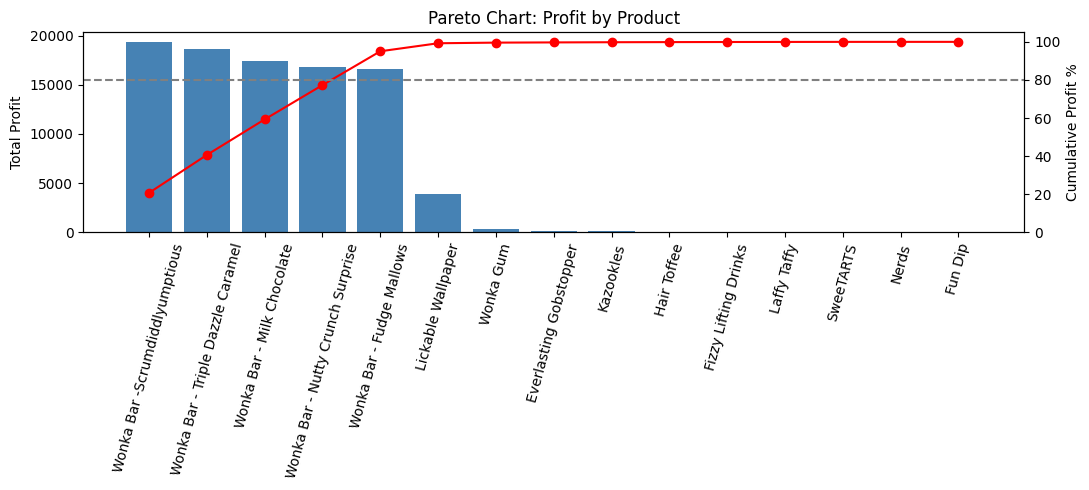

In [ ]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.bar(p_profit["Product Name"], p_profit["Total_Profit"], color="steelblue")
ax1.set_ylabel("Total Profit")
ax1.tick_params(axis="x", rotation=75)

ax2 = ax1.twinx()
ax2.plot(p_profit["Product Name"], p_profit["Cum Profit %"], color="red", marker="o")
ax2.axhline(80, color="gray", linestyle="--")
ax2.set_ylabel("Cumulative Profit %")
ax2.set_ylim(0, 105)

plt.title("Pareto Chart: Profit by Product")
plt.tight_layout()
plt.show()

In [ ]:
product["Cost to Sales %"] = product["Total_Cost"] / product["Total_Sales"] * 100
product["Cost per Unit"] = product["Total_Cost"] / product["Total_Units"]
product["Price per Unit"] = product["Total_Sales"] / product["Total_Units"]

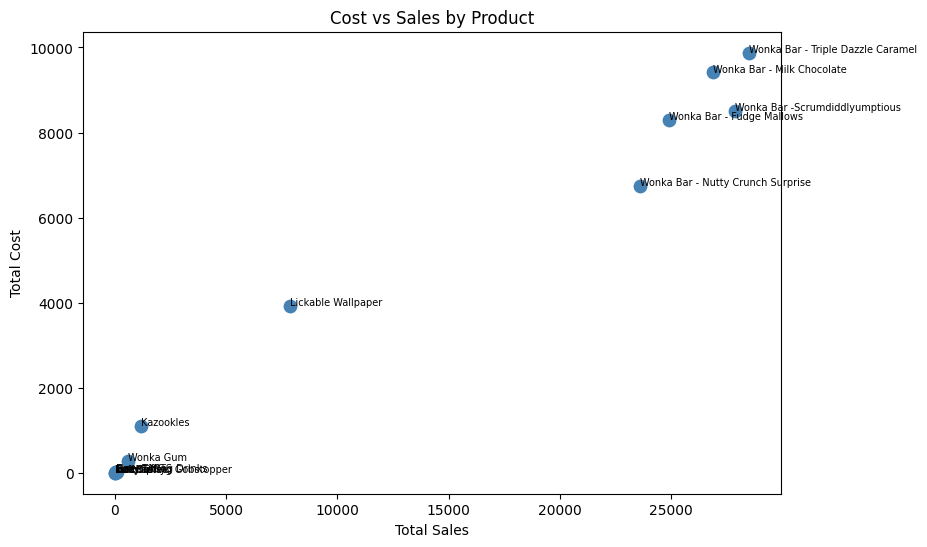

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))
plt.scatter(product["Total_Sales"], product["Total_Cost"], s=80, color="steelblue")

for _, r in product.iterrows():
    plt.annotate(r["Product Name"], (r["Total_Sales"], r["Total_Cost"]), fontsize=7)

plt.xlabel("Total Sales")
plt.ylabel("Total Cost")
plt.title("Cost vs Sales by Product")
plt.show()

In [ ]:
sales_cut = product["Total_Sales"].median()
margin_cut = product["Total_Profit"].sum() / product["Total_Sales"].sum() * 100

def flag(row):
    low_margin = row["Gross Margin %"] < margin_cut
    high_sales = row["Total_Sales"] >= sales_cut
    if low_margin and high_sales:
        return "Reprice / Renegotiate Cost"
    elif low_margin and not high_sales:
        return "Discontinuation Review"
    else:
        return "Healthy"

product["Action Flag"] = product.apply(flag, axis=1)

In [ ]:
product[["Product Name", "Division", "Total_Sales", "Gross Margin %",
         "Cost to Sales %", "Cost per Unit", "Price per Unit", "Action Flag"]].round(2).sort_values("Gross Margin %")

,Product Name,Division,Total_Sales,Gross Margin %,Cost to Sales %,Cost per Unit,Price per Unit,Action Flag
4,Kazookles,Other,1205.75,7.69,92.31,3.00,3.25,Reprice / Renegotiate Cost
2,Fun Dip,Sugar,12.00,40.00,60.00,0.90,1.50,Discontinuation Review
7,Nerds,Sugar,15.00,46.67,53.33,0.80,1.50,Discontinuation Review
8,SweeTARTS,Sugar,61.50,46.67,53.33,0.80,1.50,Discontinuation Review
6,Lickable Wallpaper,Other,7860.00,50.00,50.00,10.00,20.00,Reprice / Renegotiate Cost
14,Wonka Gum,Other,597.50,52.00,48.00,0.60,1.25,Reprice / Renegotiate Cost
1,Fizzy Lifting Drinks,Sugar,78.75,60.00,40.00,1.50,3.75,Discontinuation Review
5,Laffy Taffy,Sugar,53.73,62.31,37.69,0.75,1.99,Discontinuation Review
10,Wonka Bar - Milk Chocolate,Chocolate,26867.75,64.92,35.08,1.14,3.25,Reprice / Renegotiate Cost
12,Wonka Bar - Triple Dazzle Caramel,Chocolate,28485.00,65.33,34.67,1.30,3.75,Reprice / Renegotiate Cost


In [ ]:
tolerance = 3  # percentage points below benchmark still counts as borderline

def flag_v2(row):
    gap = row["Gross Margin %"] - margin_cut
    high_sales = row["Total_Sales"] >= sales_cut
    if gap >= 0:
        return "Healthy"
    elif gap >= -tolerance:
        return "Monitor (Borderline)"
    elif high_sales:
        return "Reprice / Renegotiate Cost"
    else:
        return "Discontinuation Review"

product["Action Flag v2"] = product.apply(flag_v2, axis=1)
product[["Product Name", "Gross Margin %", "Action Flag", "Action Flag v2"]].round(2)

,Product Name,Gross Margin %,Action Flag,Action Flag v2
13,Wonka Bar -Scrumdiddlyumptious,69.44,Healthy,Healthy
12,Wonka Bar - Triple Dazzle Caramel,65.33,Reprice / Renegotiate Cost,Monitor (Borderline)
10,Wonka Bar - Milk Chocolate,64.92,Reprice / Renegotiate Cost,Monitor (Borderline)
11,Wonka Bar - Nutty Crunch Surprise,71.35,Healthy,Healthy
9,Wonka Bar - Fudge Mallows,66.67,Healthy,Healthy
6,Lickable Wallpaper,50.00,Reprice / Renegotiate Cost,Reprice / Renegotiate Cost
14,Wonka Gum,52.00,Reprice / Renegotiate Cost,Reprice / Renegotiate Cost
0,Everlasting Gobstopper,80.00,Healthy,Healthy
4,Kazookles,7.69,Reprice / Renegotiate Cost,Reprice / Renegotiate Cost
3,Hair Toffee,77.78,Healthy,Healthy


In [ ]:
cols = ["Row ID", "Order ID", "Order Date", "Ship Date", "Ship Mode", "Customer ID",
        "Country/Region", "City", "State/Province", "Postal Code", "Division", "Region",
        "Product ID", "Product Name", "Sales", "Units", "Gross Profit", "Cost"]

out = df[cols].copy()
out.columns = [c.lower().replace(" ", "_").replace("/", "_") for c in out.columns]
out["order_date"] = out["order_date"].dt.strftime("%Y-%m-%d")
out["ship_date"] = out["ship_date"].dt.strftime("%Y-%m-%d")

print(out.shape)
print(out.columns.tolist())

out.to_csv("nassau_clean.csv", index=False)

from google.colab import files
files.download("nassau_clean.csv")

(10194, 18)
['row_id', 'order_id', 'order_date', 'ship_date', 'ship_mode', 'customer_id', 'country_region', 'city', 'state_province', 'postal_code', 'division', 'region', 'product_id', 'product_name', 'sales', 'units', 'gross_profit', 'cost']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
unique_divisions = df['Division'].unique()
num_divisions = len(unique_divisions)
print(f"There are {num_divisions} types of divisions:")
for div in unique_divisions:
    print(f"- {div}")

There are 3 types of divisions:
- Chocolate
- Other
- Sugar


In [ ]:
unique_products = df['Product Name'].unique()
num_products = len(unique_products)
print(f"There are {num_products} unique products:")
count=0
for prod in sorted(unique_products):
    print(f"- {prod}")
    count+=1
print(count)

There are 15 unique products:
- Everlasting Gobstopper
- Fizzy Lifting Drinks
- Fun Dip
- Hair Toffee
- Kazookles
- Laffy Taffy
- Lickable Wallpaper
- Nerds
- SweeTARTS
- Wonka Bar - Fudge Mallows
- Wonka Bar - Milk Chocolate
- Wonka Bar - Nutty Crunch Surprise
- Wonka Bar - Triple Dazzle Caramel
- Wonka Bar -Scrumdiddlyumptious
- Wonka Gum
15


In [ ]:
print(df["Order Date"].min(), df["Order Date"].max())

2024-01-02 00:00:00 2025-12-31 00:00:00
